# Image Processing and Computer Vision Lab

In [1]:
import cv2, numpy as np
import matplotlib.pyplot as plt

## Problem 1 - Sampling and Quantization

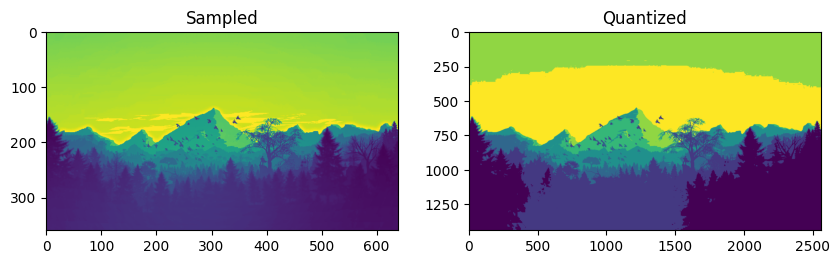

In [2]:
im = cv2.imread('mountains.jpg',0)

s = 4
sm = im[::s,::s]

L = 8
lv = 256//L
q = (im//lv)*lv

plt.figure(figsize=(10,4))

plt.subplot(121)
plt.imshow(sm)
plt.title('Sampled')

plt.subplot(122)
plt.imshow(q)
plt.title('Quantized')

plt.show()

## Histogram Analysis

/tmp/ipykernel_68385/1017732924.py:4: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(im.ravel(),256,[0,256])
/tmp/ipykernel_68385/1017732924.py:8: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(q.ravel(),256,[0,256])


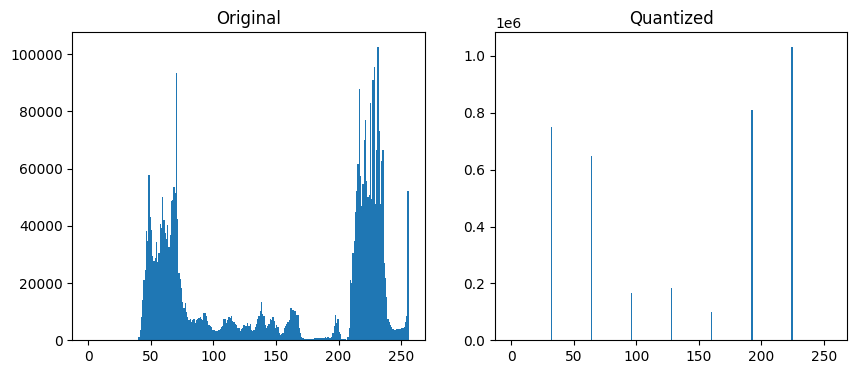

152.80685980902777
137.60061631944444


In [3]:
plt.figure(figsize=(10,4))

plt.subplot(121)
plt.hist(im.ravel(),256,[0,256])
plt.title('Original')

plt.subplot(122)
plt.hist(q.ravel(),256,[0,256])
plt.title('Quantized')

plt.show()

print(im.mean())
print(q.mean())

## 1D FFT Along Rows and Columns

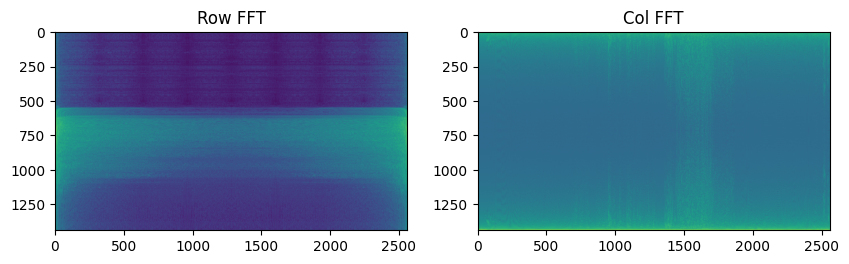

In [4]:
fr = np.fft.fft(im,axis=1)
fc = np.fft.fft(im,axis=0)

plt.figure(figsize=(10,4))

plt.subplot(121)
plt.imshow(np.log(1+np.abs(fr)))
plt.title('Row FFT')

plt.subplot(122)
plt.imshow(np.log(1+np.abs(fc)))
plt.title('Col FFT')

plt.show()

## 2D FFT

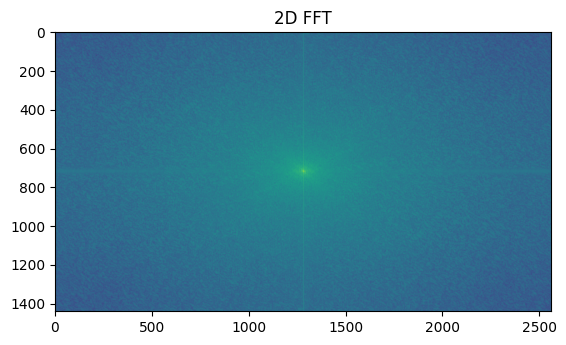

In [5]:
f = np.fft.fft2(im)

fs = np.fft.fftshift(f)

m = np.log(1+np.abs(fs))

plt.imshow(m)
plt.title('2D FFT')

plt.show()

## Manual DCT Matrix Implementation

In [6]:
g = np.float32(im)

r,c = g.shape

A = np.zeros((r,r))

for i in range(r):
    for j in range(r):
        if i == 0:
            A[i,j] = np.sqrt(1/r)
        else:
            A[i,j] = np.sqrt(2/r)*np.cos(((2*j+1)*i*np.pi)/(2*r))

d = A@g@A.T

s = np.log(1+np.abs(d))

plt.imshow(s)
plt.title('DCT')

plt.show()

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 1440 is different from 2560)

## Ideal Low Pass Filter

In [ ]:
f = np.fft.fft2(im)

fs = np.fft.fftshift(f)

r,c = im.shape

u,v = np.meshgrid(np.arange(c),np.arange(r))

cx,cy = c//2,r//2

D = np.sqrt((u-cx)**2 + (v-cy)**2)

d0 = 40

h = np.zeros((r,c))
h[D<=d0] = 1

g = fs*h

o = np.fft.ifft2(np.fft.ifftshift(g))
o = np.abs(o)

plt.imshow(o)
plt.title('ILPF')

plt.show()

## Butterworth Low Pass Filter

In [ ]:
f = np.fft.fft2(im)

fs = np.fft.fftshift(f)

r,c = im.shape

u,v = np.meshgrid(np.arange(c),np.arange(r))

cx,cy = c//2,r//2

D = np.sqrt((u-cx)**2 + (v-cy)**2)

d0 = 40
n = 2

h = 1/(1+(D/d0)**(2*n))

g = fs*h

o = np.fft.ifft2(np.fft.ifftshift(g))
o = np.abs(o)

plt.imshow(o)
plt.title('BLPF')

plt.show()

## Gaussian Low Pass Filter

In [ ]:
f = np.fft.fft2(im)

fs = np.fft.fftshift(f)

r,c = im.shape

u,v = np.meshgrid(np.arange(c),np.arange(r))

cx,cy = c//2,r//2

D2 = (u-cx)**2 + (v-cy)**2

d0 = 40

h = np.exp(-D2/(2*d0*d0))

g = fs*h

o = np.fft.ifft2(np.fft.ifftshift(g))
o = np.abs(o)

plt.imshow(o)
plt.title('GLPF')

plt.show()

## Ideal High Pass Filter

In [ ]:
f = np.fft.fft2(im)

fs = np.fft.fftshift(f)

r,c = im.shape

u,v = np.meshgrid(np.arange(c),np.arange(r))

cx,cy = c//2,r//2

D = np.sqrt((u-cx)**2 + (v-cy)**2)

d0 = 40

h = np.ones((r,c))
h[D<=d0] = 0

g = fs*h

o = np.fft.ifft2(np.fft.ifftshift(g))
o = np.abs(o)

plt.imshow(o)
plt.title('IHPF')

plt.show()

## Butterworth High Pass Filter

In [ ]:
f = np.fft.fft2(im)

fs = np.fft.fftshift(f)

r,c = im.shape

u,v = np.meshgrid(np.arange(c),np.arange(r))

cx,cy = c//2,r//2

D = np.sqrt((u-cx)**2 + (v-cy)**2)

d0 = 40
n = 2

h = 1 - 1/(1+(D/d0)**(2*n))

g = fs*h

o = np.fft.ifft2(np.fft.ifftshift(g))
o = np.abs(o)

plt.imshow(o)
plt.title('BHPF')

plt.show()

## High Boost Filtering

In [ ]:
f = np.fft.fft2(im)

fs = np.fft.fftshift(f)

r,c = im.shape

u,v = np.meshgrid(np.arange(c),np.arange(r))

cx,cy = c//2,r//2

D2 = (u-cx)**2 + (v-cy)**2

d0 = 30

h = 1 - np.exp(-D2/(2*d0*d0))

k = 2

hb = 1 + k*h

g = fs*hb

o = np.fft.ifft2(np.fft.ifftshift(g))
o = np.abs(o)

plt.imshow(o)
plt.title('High Boost')

plt.show()

## Homomorphic Filtering

In [ ]:
g = np.float32(im)+1

l = np.log(g)

f = np.fft.fft2(l)

fs = np.fft.fftshift(f)

r,c = im.shape

u,v = np.meshgrid(np.arange(c),np.arange(r))

cx,cy = c//2,r//2

D2 = (u-cx)**2 + (v-cy)**2

rh = 2
rl = 0.5
d0 = 30

h = (rh-rl)*(1-np.exp(-D2/(2*d0*d0))) + rl

g = fs*h

o = np.fft.ifft2(np.fft.ifftshift(g))

o = np.exp(np.real(o))

plt.imshow(o)
plt.title('Homomorphic')

plt.show()